In [1]:
import numpy as np
import time
import tqdm as tqdm
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, Get_Two_as_dens, Get_Two_as_pres

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

* calculate and get a number for $C$
* $z(t) = (z^{1/2}_1 - \frac{C}{2}(t - t_1))^2$, where $v_{N\to Q} = C \sqrt{z}$. choose a $t^\prime$, compare numerical solution and analytical from window $(t^\prime\sim t_1)$

# Getting numbers for $C$

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
from fractions import Fraction

# Read CSV (skip the header row if it exists)
df1 = pd.read_csv("pressure_of_radius_pMeV4_3n0.csv")
df2 = pd.read_csv("pressure_of_radius_pMeV4_4n0.csv")
df3 = pd.read_csv("pressure_of_radius_pMeV4_4.5n0.csv")

# Convert the first column (fractions as strings) to floats
radius1 = df1.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure1 = df1.iloc[:, 1]

radius2 = df2.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure2 = df2.iloc[:, 1]

radius3 = df3.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure3 = df3.iloc[:, 1]

# Convert to numpy arrays if needed
radius1 = radius1.to_numpy(dtype=float)
radius2 = radius2.to_numpy(dtype=float)
radius3 = radius3.to_numpy(dtype=float)
pressure1 = pressure1.to_numpy(dtype=float)
pressure2 = pressure2.to_numpy(dtype=float)
pressure3 = pressure3.to_numpy(dtype=float)

P_of_r1 = interp1d(radius1, pressure1, kind="linear", fill_value="extrapolate")
P_of_r2 = interp1d(radius2, pressure2, kind="linear", fill_value="extrapolate")
P_of_r3 = interp1d(radius3, pressure3, kind="linear", fill_value="extrapolate")

r_test1 = np.linspace(radius1.min(), radius1.max(), 100)
r_test2 = np.linspace(radius2.min(), radius2.max(), 100)
r_test3 = np.linspace(radius3.min(), radius3.max(), 100)
P_test1 = np.array([P_of_r1(ele) for ele in r_test1])
P_test2 = np.array([P_of_r2(ele) for ele in r_test2])
P_test3 = np.array([P_of_r3(ele) for ele in r_test3])

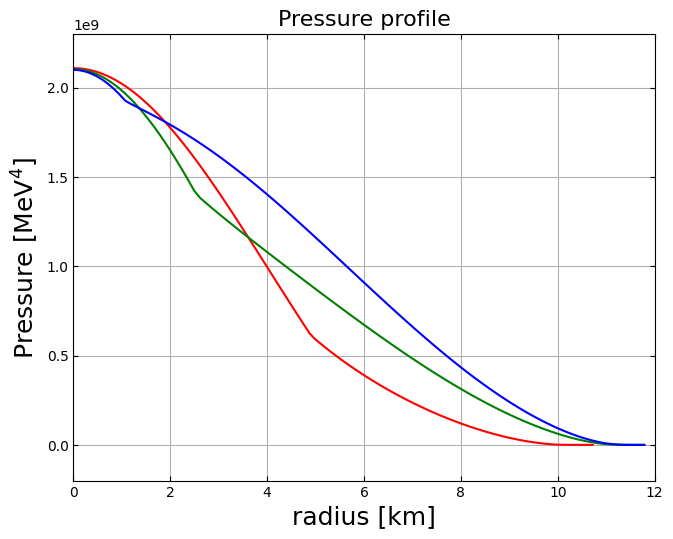

In [3]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(r_test1, P_test1, 'r')
plt.plot(r_test2, P_test2, 'g')
plt.plot(r_test3, P_test3, 'b')

#plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
#plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)

plt.xlim(0, 12)
plt.ylim(-0.2e+9, 2.3e+9)
plt.tick_params(which='both', direction='in', top=True, right=True)

plt.grid()
plt.show()

In [4]:
T_set = 15
n_kink1 = 3.0 * n0
n_kink2 = 4.0 * n0
n_kink3 = 4.5 * n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"


# solve for bag constant
P_kink1 = PNM_n(n_kink1, T_set)
P_kink2 = PNM_n(n_kink2, T_set)
P_kink3 = PNM_n(n_kink3, T_set)

In [8]:
from RMFsolver.phase_velocity import z_time_evolution1
from tqdm import tqdm

Temp_list = [0.1, 1, 10, 50]

t1 = []
z1 = []
t2 = []
z2 = []
t3 = []
z3 = []
P_cr1 = []
P_cr2 = []
P_cr3 = []

time_up = 150

for Te in tqdm(Temp_list):
    tt1, zz1, P_crit1 = z_time_evolution1(
        Pressure_arr = pressure1, 
        radius_arr = radius1,
        P_kink = P_kink1,
        T = Te, 
        z0 = 1,
        Interp1d_Num = 20,
        t_up = time_up,
    )
    
    tt2, zz2, P_crit2 = z_time_evolution1(
        Pressure_arr = pressure2, 
        radius_arr = radius2,
        P_kink = P_kink2,
        T = Te, 
        z0 = 1,
        Interp1d_Num = 20,
        t_up = time_up,
    )
    
    tt3, zz3, P_crit3 = z_time_evolution1(
        Pressure_arr = pressure3, 
        radius_arr = radius3,
        P_kink = P_kink3,
        T = Te, 
        z0 = 1,
        Interp1d_Num = 20,
        t_up = time_up,
    )

    t1.append(tt1)
    z1.append(zz1)
    
    t2.append(tt2)
    z2.append(zz2)

    t3.append(tt3)
    z3.append(zz3)

    P_cr1.append(P_crit1)
    P_cr2.append(P_crit2)
    P_cr3.append(P_crit3)


00%|██████████████████████████████████████████████| 4/4 [35:00<00:00, 525.17s/it]

In [9]:
n_cr1 = []
n_cr2 = []
n_cr3 = []

for i in tqdm(range(len(Temp_list))):
    
    n_crit1 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr1[i], x0=3.0*n0)[0]
    n_crit2 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr2[i], x0=3.0*n0)[0]
    n_crit3 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr3[i], x0=3.0*n0)[0]

    n_cr1.append(n_crit1)
    n_cr2.append(n_crit2)
    n_cr3.append(n_crit3)


00%|███████████████████████████████████████████████| 4/4 [00:35<00:00,  8.85s/it]

Text(0, 0.5, '$z$ [$\\mathrm{km}$]')

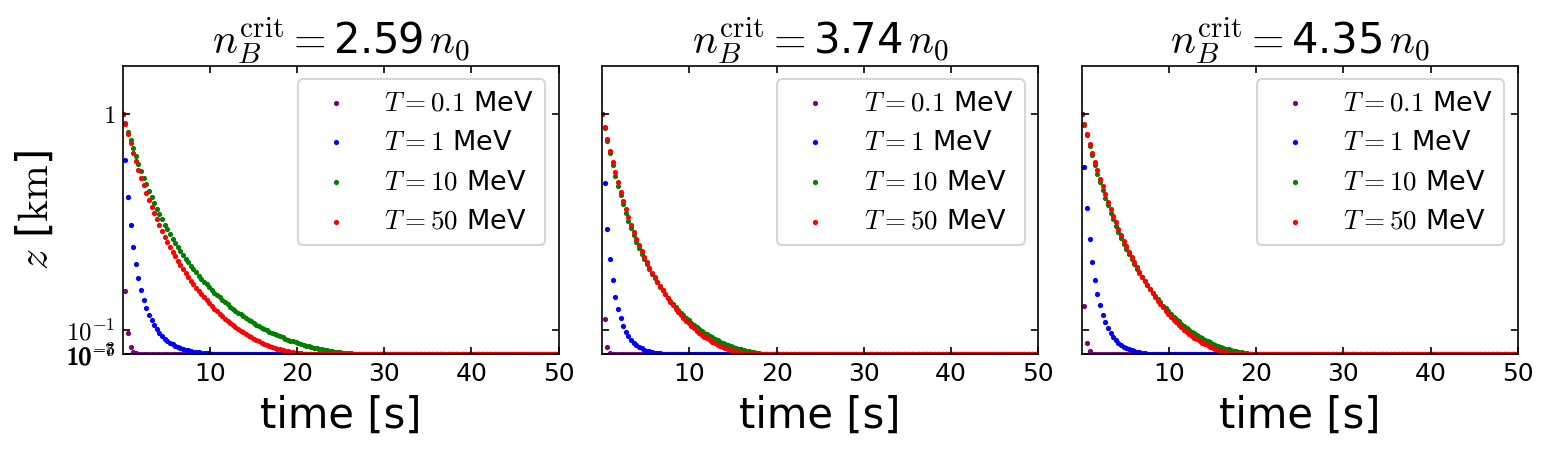

In [54]:
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt

# --- style ---
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern math
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig, axs = plt.subplots(1, 3, figsize=(12, 2.5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

t_upp = 50
y_down = 1e-15
tline = np.linspace(0, t_upp, 100)
zeroline = np.zeros_like(tline)

# helper for panel titles
def crit_title(mean_n_over_n0):
    return r"$n_B^{\mathrm{crit}} = $" + f"{mean_n_over_n0:.2f}" + r"$\,n_0$"

# color scheme for temperatures
colors = ['purple', 'b', 'g', 'r']
labels = [r"$T=0.1$ MeV", r"$T=1$ MeV", r"$T=10$ MeV", r"$T=50$ MeV"]

# define y ticks (10^0 down to 10^-7)
y_ticks = [1e0, 1e-1, 1e-3, 1e-5, 1e-7]
y_ticklabels = [r"$1$", r"$10^{-1}$", r"$10^{-3}$",
                r"$10^{-5}$", r"$10^{-7}$"]

# ---------- panel loop ----------
for ax, tset, zset, ncr in zip(axs, [t1, t2, t3], [z1, z2, z3], [n_cr1, n_cr2, n_cr3]):
    for c, lbl, t, z in zip(colors, labels, tset, zset):
        ax.scatter(t, z, lw=1.5, c=c, label=lbl, s=1)
    ax.plot(tline, zeroline, c='k', lw=1)
    ax.set_xlim(5e-4, t_upp)
    ax.set_ylim(y_down, 1.2)
    #ax.set_yscale("log")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_ticklabels)
    ax.set_xlabel(r"time [s]", fontsize=20)
    ax.set_title(crit_title(np.mean(ncr) / n0), fontsize=20)
    ax.tick_params(which='both', direction='in', top=True, right=True)
    ax.legend(fontsize=13, loc="upper right", frameon=True)

axs[0].set_ylabel(r"$z$ [$\mathrm{km}$]", fontsize=20)

#plt.savefig("Various_z(t)_new_idea_log.pdf", bbox_inches="tight")
# plt.show()

The proportionality factor have the following structure:
$$
C = \frac{1}{a_N}
\times
\sqrt{\frac{2D_Q\eta_Q\gamma_Q\chi_K^Q}{n_B^Q}}
\times
\left\{
\left.\frac{\partial P}{\partial r}\right|_{\rm crit}\cdot
\left[
\Big(\left.\frac{\partial P_{PNM}}{\partial \mu_B}\right|_{\rm crit}\Big)^{-1} - \Big(\left.\frac{\partial P_{SQM}}{\partial \mu_B}\right|_{\rm crit}\Big)^{-1}
\right]
\right\}^{1/2}
$$
to calculate it, need the following info. $\mu_B^{\rm crit}, \, \Delta P,\, T$ and pressure profile [P, r]

In [5]:
def C_factor(T, P_crit, DeltaP, Pressure, Radius):
    '''
    Computes the C factor for vNtoQ = C * sqrt(z)

    Parameters:
    - T        : temperature [MeV]
    - P_crit   : critical pressure [MeV^4]
    - DeltaP   : pressure difference between critical pressure and pressure of the phase boundary [MeV^4]
    - Pressure : array-like, pressure profile of P(r)
    - Radius   : array-like, radius array of P(r)

    Returns:
    - C        : in units of [km]^1/2 * s^-1
    '''
    
    #Radius *= 1e18 / const.MeV_fm  # convert from km to MeV^-1
    muB_crit = fsolve(lambda x: PNM(x, T) - P_crit, 1000)[0]
    B_SQM = fsolve(lambda x: PQM(muB_crit, 0, x, T) - P_crit, 100)[0]
    muB_Q = fsolve(lambda x: PQM(x, 0, B_SQM, T) - (P_crit + DeltaP), 1000)[0]
    muQ = muB_Q/3
    muB_N = fsolve(lambda x: PNM(x, T) - (P_crit + DeltaP), 1000)[0]
    
    alpha_s = 0.3
    g_s = np.sqrt(4 * np.pi * alpha_s)
    
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    gammaQ = 1/tauQ
    qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h = 1.81317
    part1 = h*T**(5/3)/qD**(2/3)
    part2 = np.pi**3 * T**2 / (12*qD)
    DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
    
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    dPNM_dmuB = Derivative(lambda x: PNM(x, T), n=1)
    
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nB_N = dPNM_dmuB(muB_N)
    nK_Q = dPQM_dmuK(0)
    aN = (nB_N - nK_Q) / nB_Q
    
    dPQM_dmuB_crit = dPQM_dmuB(muB_crit)
    dPNM_dmuB_crit = dPNM_dmuB(muB_crit)
    
    P_of_r = interp1d(Radius, Pressure, kind="linear", fill_value="extrapolate")
    r_crit = fsolve(lambda x: P_of_r(x) - P_crit, 10)[0]
    dP_dr = Derivative(P_of_r1, n=1)
    dP_dr_crit = dP_dr(r_crit) 
    dP_dr_crit *= const.MeV_fm / 1e18
    
    C = (1/aN) * np.sqrt(DQ * etaQ * gammaQ * 2 * chiK_Q/ nB_Q) * np.sqrt(np.abs(dP_dr_crit) * ((1/dPNM_dmuB_crit) - (1/dPQM_dmuB_crit)))

    return 2.137e13 * C

$$
C^2 = 
\frac{2D_Q\eta_Q\gamma_Q\chi_K^{\bar Q}}{a_{\bar N}^2\,n_B^{\bar Q}} \,
\frac{\partial P}{\partial z} \,
\biggl(
\frac{1}{n_{B}^{\bar N}} - \frac{1}{n_{B}^{\bar Q}}
\biggr) 
$$

add more information to this latex code such that it takes care of the last \mgacom. so basically the idea is to use the formula for C^2, put in typical numbers and obtain that in units of km^1/2 * s^-1, C factor has numerical value of 0.05. Typical value of the parameters are listed as:

(1) for DQ*gammaQ, see details in this text:

At merger temperatures $T>1\,\MeV$ the maximum boundary speed is in the range of
$10^2$ to $10^4 \,\m\,\s^{-1}$. This is understandable from Eq.~\eqref{eq:v_analytical}: the kaon-ness fractions
are expected to be of order 1, so typically $\vb^\text{max}\sim \sqrt{\gamma_Q D_Q}$ which in the low temperature regime is of order $0.03\,(\alpha_w/\alpha_s) (\mu_q/M_W)^2(\mu_q/T)^{5/6}$, so even at the lowest temperatures we study it is heavily suppressed by the mass of the W boson, i.e., by the slowness of the weak interaction. 
%\mgacom{I dropped a factor of $\alpha_s^{1/6}$ because it's close to 1} 
For example, under plausible merger conditions such as $\mu_q=300\,\MeV$ and $T = 5\,\MeV$ we obtain  $\vb^\text{max} \sim 13\,\m\,\s^{-1}$.

(2)
DQ =  0.2725325883812444
etaQ =  0.11098047082902529
gammaQ =  2.8603821625558844e-12
chiK_Q =  27482.18023916492
aN =  0.5940691400116224
nB_Q =  7838630.1909639705
dP/dr =  3.9465392e-08
nB_NM =  3675453.1329935617
nB_QM =  6390012.38866098

be ware of units!!!, all numbers above are in natural units t.e. various powers of MeV. convert back when necessary. for example, dP/dr = 2e8 MeV^4/km. 

here's the text to update. don't change what's already written. just add information in the end

We can understand this time scale by considering the last part of the evolution, where $z$ is small, meaning the phase boundary is close to its equilibrium position.
In this limit, the difference between the baryon chemical potentials in the two phases at the boundary tends to zero, so $\aQstar^{\rm max}$ and $\vb$ also go to zero (Eq.~\eqref{eq:aQmax}). 
We can then expand Eq.~\eqref{eq:v_analytical} to leading order in $\aQstar$, 
\begin{equation}
    \vb^2 = D_Q\eta_Q\gamma_Q\left(\frac{\aQstar}{a_\Nbar}\right)^2\ ,
\end{equation}
and from Eq.~\eqref{eq:aQmax} we obtain the small-$z$ result,
\begin{align}
 \frac{dz}{dt} &= -C\,z^{1/2} \ , \\
 C^2 &= 
\frac{2D_Q\eta_Q\gamma_Q\chi_K^\Qbar}{a_\Nbar^2\,n_B^\Qbar} \,
\frac{\partial P}{\partial z} \,
\biggl(
\frac{1}{n_{B}^\Nbar} - \frac{1}{n_{B}^\Qbar}
\biggr) \ ,
 \label{eq:v_asymptotic}
\end{align}
where quantities labeled with \Nbar\ or \Qbar\ are evaluated
at the critical point. The solution is
\begin{equation}
    z(t) = \Bigl(z_0^{1/2} - \frac{C}{2}t \Bigr)^2 ,\;\label{eq:z(t)_analytical}
\end{equation}
and since $z(\tfinal)=0$ we obtain
\begin{equation}
\tfinal = \dfrac{2 z_0^{1/2}}{C} \ .
\end{equation}
}
This solution makes it explicit that the interface decelerates as it evolves and reaches the critical point in a finite time.
\mgacom{Say something about typical values of $C$?}

In [10]:
def C_factor_dP_dr(T, P_crit, DeltaP, dP_over_dr):
    '''
    Computes the C factor for vNtoQ = C * sqrt(z)

    Parameters:
    - T          : temperature [MeV]
    - P_crit     : critical pressure [MeV^4]
    - DeltaP     : pressure difference between critical pressure and pressure of the phase boundary [MeV^4]
    - dP_over_dr : in units of MeV^4/km

    Returns:
    - C        : in units of [km]^1/2 * s^-1
    '''
    
    #Radius *= 1e18 / const.MeV_fm  # convert from km to MeV^-1
    muB_crit = fsolve(lambda x: PNM(x, T) - P_crit, 1000)[0]
    B_SQM = fsolve(lambda x: PQM(muB_crit, 0, x, T) - P_crit, 100)[0]
    muB_Q = fsolve(lambda x: PQM(x, 0, B_SQM, T) - (P_crit + DeltaP), 1000)[0]
    muQ = muB_Q/3
    muB_N = fsolve(lambda x: PNM(x, T) - (P_crit + DeltaP), 1000)[0]
    
    alpha_s = 0.3
    g_s = np.sqrt(4 * np.pi * alpha_s)
    
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    gammaQ = 1/tauQ
    qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h = 1.81317
    part1 = h*T**(5/3)/qD**(2/3)
    part2 = np.pi**3 * T**2 / (12*qD)
    DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
    
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    dPNM_dmuB = Derivative(lambda x: PNM(x, T), n=1)
    
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nB_N = dPNM_dmuB(muB_N)
    nK_Q = dPQM_dmuK(0)
    aN = (nB_N - nK_Q) / nB_Q
    
    dPQM_dmuB_crit = dPQM_dmuB(muB_crit)
    dPNM_dmuB_crit = dPNM_dmuB(muB_crit)
    
    dP_over_dr *= const.MeV_fm / 1e18

    print("DQ = ", DQ)
    print("etaQ = ", etaQ)
    print("gammaQ = ", gammaQ)
    print("chiK_Q = ", chiK_Q)
    print("aN = ", aN)
    print("nB_Q = ", nB_Q)
    print("dP/dr = ", dP_over_dr)
    print("nB_NM = ", dPNM_dmuB_crit)
    print("nB_QM = ", dPQM_dmuB_crit)
    C = (1/aN) * np.sqrt(DQ * etaQ * gammaQ * 2 * chiK_Q/ nB_Q) * np.sqrt(np.abs(dP_over_dr) * ((1/dPNM_dmuB_crit) - (1/dPQM_dmuB_crit)))

    return 2.137e13 * C

In [11]:
C_factor_dP_dr(T = 15, P_crit = 6.1e8, DeltaP = 6e8, dP_over_dr = 2e8), 

DQ =  0.2725325883812444
etaQ =  0.11098047082902529
gammaQ =  2.8603821625558844e-12
chiK_Q =  27482.18023916492
aN =  0.5940691400116224
nB_Q =  7838630.1909639705
dP/dr =  3.9465392e-08
nB_NM =  3675453.1329935617
nB_QM =  6390012.38866098


(np.float64(0.05983897454287918),)

In [30]:
DQ =  0.2725325883812444
etaQ =  0.11098047082902529
gammaQ =  2.8603821625558844e-12
chiK_Q =  27482.18023916492
aN =  0.5940691400116224
nB_Q =  7838630.1909639705
dP_dr =  3.9465392e-08
nB_NM =  3675453.1329935617
nB_QM =  6390012.38866098

((etaQ*chiK_Q/(nB_Q*aN**2)) * (1/nB_NM - 1/nB_QM) * dP_dr /const.MeV_fm) * 1e18

0.0254859201212745

In [33]:
np.sqrt(0.0254859201212745) * np.sqrt(DQ*gammaQ)*3e5

np.float64(0.042285616286467174)

In [44]:
np.sqrt(DQ*gammaQ)*3e8

np.float64(264.8759368211478)

In [9]:
C_factor(15, 6.1e8, 6e8, pressure2, radius2), 

(np.float64(0.05366162860952203),)

In [35]:
nu = (3*np.pi / (24*3*1.81)) * (4*np.pi*3/(2*np.pi**2))**(2/3) * (128/(27*5*np.pi**3)) * (np.pi**2 / 2) * np.sin(0.22)**2 * np.cos(0.22)**2
np.sqrt(nu)

np.float64(0.027603439851801175)

In [38]:
 300**(1/3) *(0.3)**(1/6)

5.47722557505166

In [43]:
0.03 * (300/5)**(5/6) * (300/80000)**2 * (0.034/0.3)  * 3e8 # speed of light

434.96610526097976

### Profile-1,  $\quad n_{\rm kink} = 2.5 n_0$

Text(0, 0.5, '$\\sqrt{z}$')

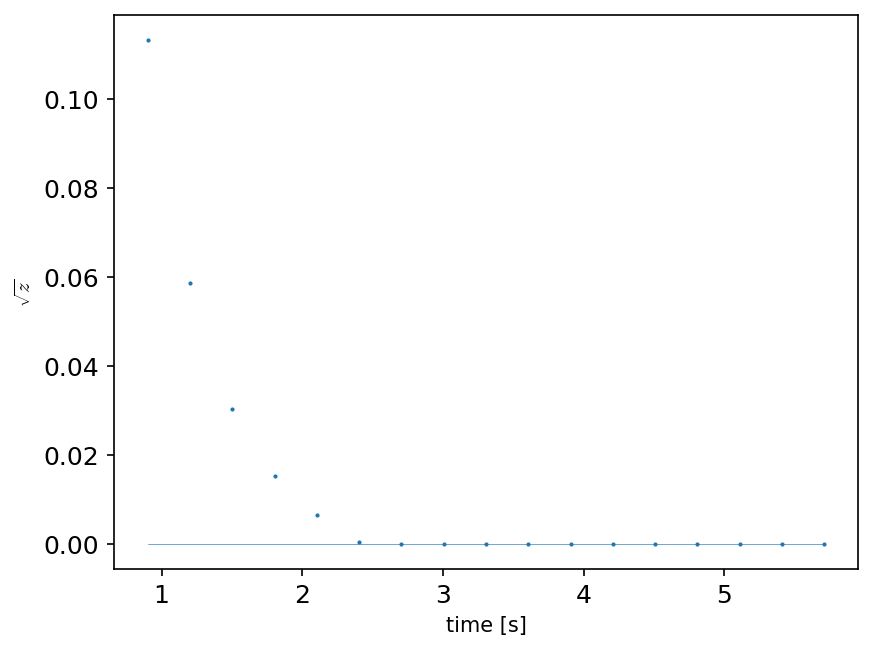

In [90]:
tt = t3[0][3:20]
zz = z3[0][3:20] - z3[0].min()
plt.scatter(tt, np.sqrt(np.abs(zz)), s=1)
plt.plot(tt, np.zeros(len(tt)), lw=0.3)
plt.xlabel("time [s]")
plt.ylabel(r"$\sqrt{z}$")
#plt.yscale('log')

In [20]:
z1[0][-1]

np.float64(-1.2349017587896461e-08)

Text(0, 0.5, '$\\sqrt{z}$')

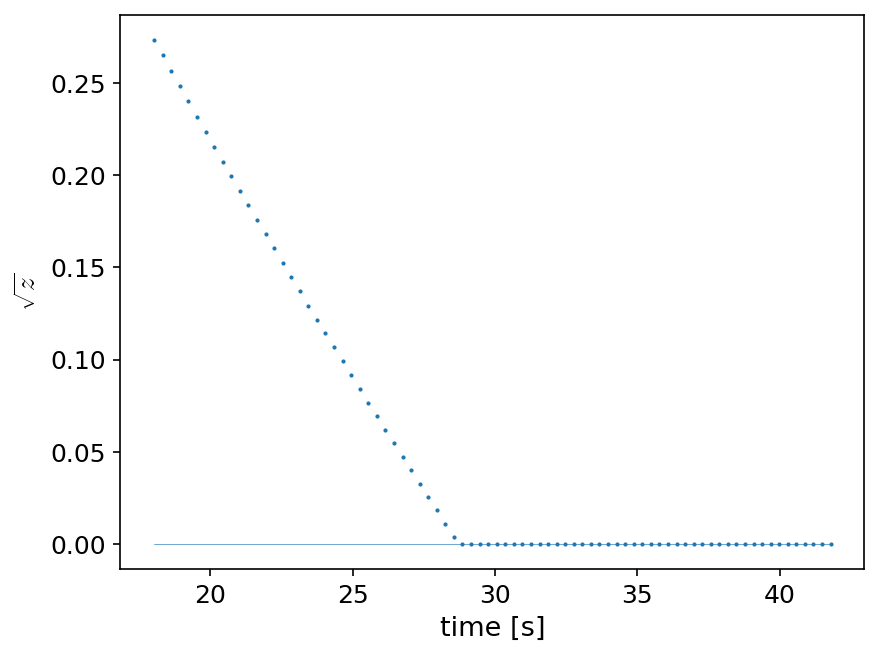

In [138]:
tt = t1[2][60:140]
zz = z1[2][60:140] - z1[2].min()
plt.scatter(tt, np.sqrt(np.abs(zz)), s=1)
plt.plot(tt, np.zeros(len(tt)), lw=0.3)
plt.xlabel("time [s]")
plt.ylabel(r"$\sqrt{z}$")
#plt.yscale('log')

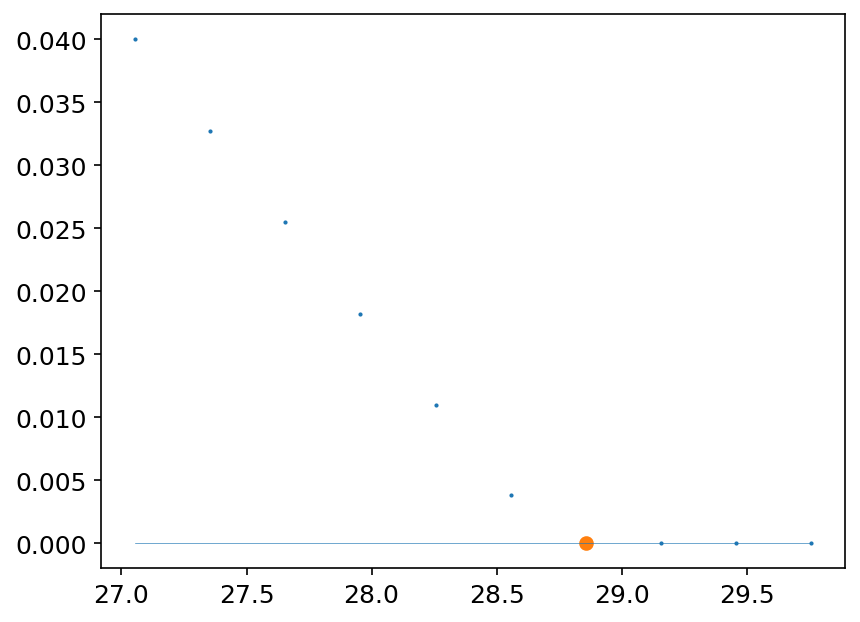

In [139]:
tt = t1[2]
zz = z1[2]- z1[2].min()
plt.scatter(tt[90:100], np.sqrt(np.abs(zz[90:100])), s=1)
plt.plot(tt[90:100], np.zeros(len(tt[90:100])), lw=0.3)
plt.scatter(tt[96], zz[96])
#plt.yscale('log')

In [21]:
zz[-1], len(zz)

(np.float64(9.620174684482241e-10), 500)

In [140]:
t_final = tt[96]
t_1 = tt[90]
z_1 = zz[90]

r_crit = fsolve(lambda x: P_of_r1(x) - P_cr1[1], 10)[0]

P_isobar = P_of_r1(r_crit - z_1)

C = C_factor(T=10, P_crit=P_cr1[1], DeltaP=P_isobar-P_cr1[1], Pressure=pressure1, Radius=radius1)
C

np.float64(0.04867601574485329)

Text(0, 0.5, '$\\sqrt{z}$')

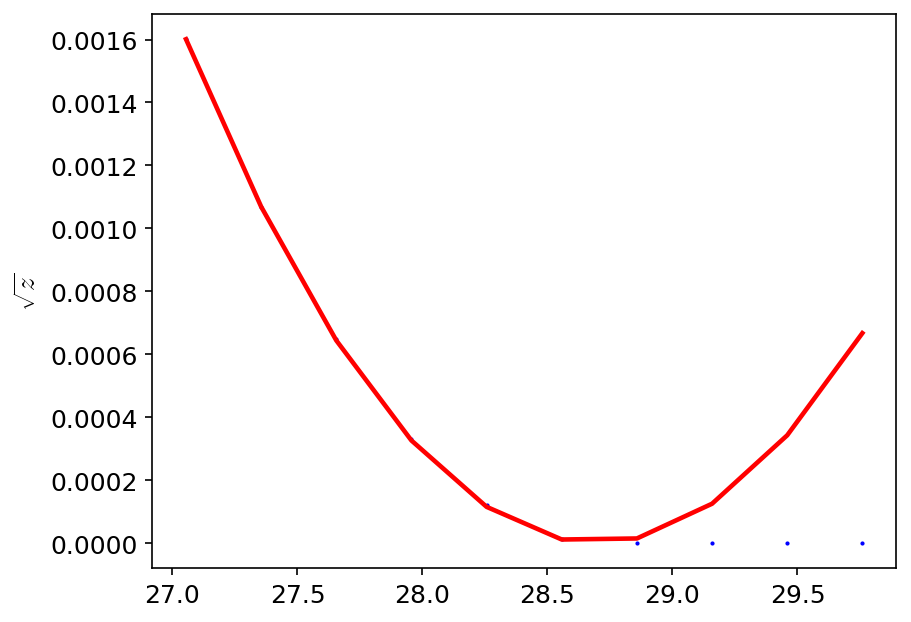

In [141]:
def z_predict(t):
    #t_nat = t * 1.52e21
    #z_nat = (np.sqrt(z_1*1e18/const.MeV_fm) - C*(t_nat - t_1*1.52e21)/2)**2
    #return z_nat * const.MeV_fm / 1e18
    return (np.sqrt(z_1) - C*(t - t_1)/2)**2

t_test = tt[90:100]
z_test = zz[90:100]

plt.scatter(t_test, np.abs(z_test), c='b', s=1)
plt.plot(t_test, [np.abs(z_predict(t_test[i])) for i in range(len(t_test))], 'r')
plt.ylabel(r"$\sqrt{z}$")
#plt.scatter(t_1, 0)

Text(0, 0.5, '$\\sqrt{z}$')

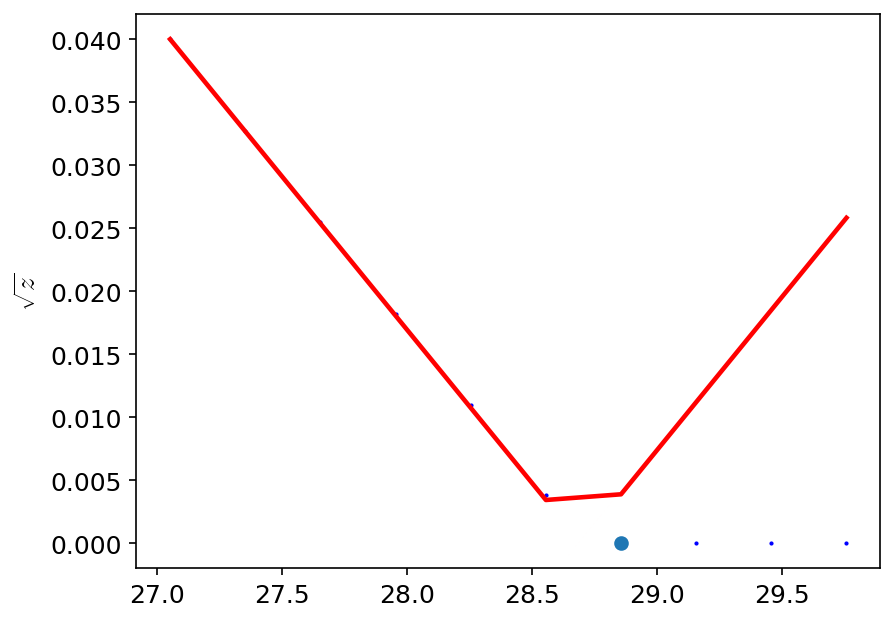

In [142]:
def z_predict(t):
    #t_nat = t * 1.52e21
    #z_nat = (np.sqrt(z_1*1e18/const.MeV_fm) - C*(t_nat - t_1*1.52e21)/2)**2
    #return z_nat * const.MeV_fm / 1e18
    return (np.sqrt(z_1) - C*(t - t_1)/2)**2

t_test = tt[90:100]
z_test = zz[90:100]

plt.scatter(t_test, np.sqrt(np.abs(z_test)), c='b', s=1)
plt.scatter(tt[96], zz[96])
plt.plot(t_test, [np.sqrt(np.abs(z_predict(t_test[i]))) for i in range(len(t_test))], 'r')
plt.ylabel(r"$\sqrt{z}$")
#plt.scatter(t_1, 0)

## Questions
* it seems numerical solution $z(t)$ at large $t$ converges to a small negative number
* unfortunately the theoretical prediction $dz/dt = -C\sqrt{z}$ completely disagrees with the mock numerical simulation. two possibilities:
  * theoretical prediction $v_{N\to Q}\propto \sqrt{z}$ is wrong
  * calculation for $C$ have errors (**more likely**)
      * solution: check formula for $C$ again
  * numerical simulation isn't stable at $<1$m scale e.g. converges to small negative number (**likely**)
      * solution: try change $z_0$ from 1km to a very small value

# To do 
* sort out this small disagreement between blue dots and red line (plugged in wong temperature) $\boxed{\checkmark}$
* streamline the formula for $C$ $\boxed{\checkmark}$
$$
C = 
\sqrt{\frac{2D_Q\eta_Q\gamma_Q\chi_K^Q}{a_N^2\,n_B^Q}}
\cdot
\left[
\frac{\partial P}{\partial r}
\left(
\frac{1}{n_{B}^{\rm NM}} - \frac{1}{n_{B}^{\rm QM}}
\right)
\right]_{\rm crit}^{1/2}
$$
* why at high $T$ the gray region bends towards lower $\Delta n$, i.e. why $a_N(T)$ bends down and $a_{Q^*}(T)$ goes up

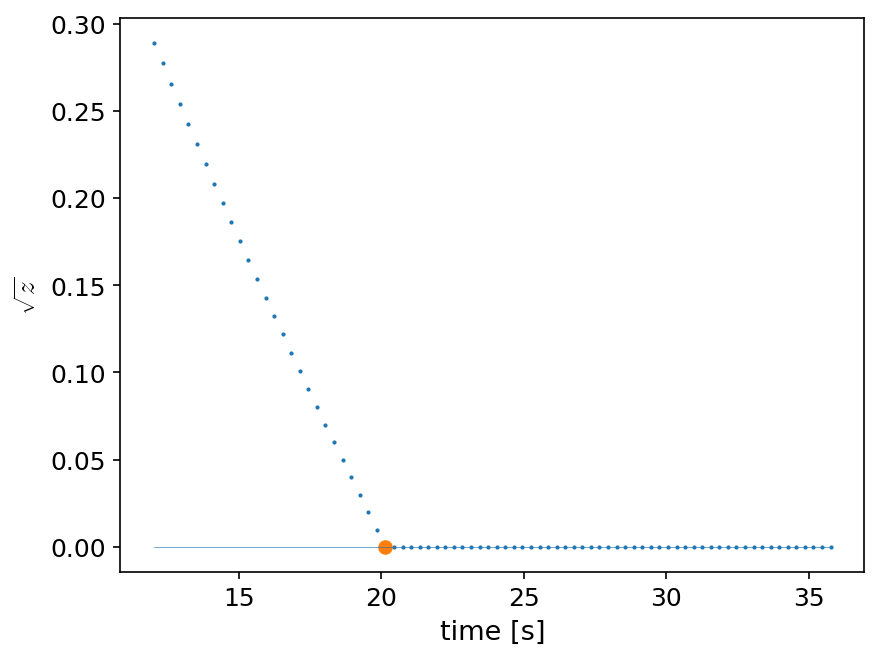

In [126]:
tt = t2[2][40:120]
zz = z2[2][40:120] - z2[2].min()
plt.scatter(tt, np.sqrt(np.abs(zz)), s=1)
plt.plot(tt, np.zeros(len(tt)), lw=0.3)
plt.xlabel("time [s]")
plt.ylabel(r"$\sqrt{z}$")
plt.scatter(tt[27], np.sqrt(zz[27]))
#plt.yscale('log')

In [134]:
t_final = tt[27]
t_1 = tt[10]
z_1 = zz[10]

r_crit = fsolve(lambda x: P_of_r2(x) - P_cr2[2], 10)[0]

P_isobar = P_of_r2(r_crit - z_1)

C = C_factor(T=10, P_crit=P_cr2[2], DeltaP=P_isobar-P_cr2[2], Pressure=pressure2, Radius=radius2)
C

np.float64(0.06710959803409508)

Text(0, 0.5, '$\\sqrt{z}$')

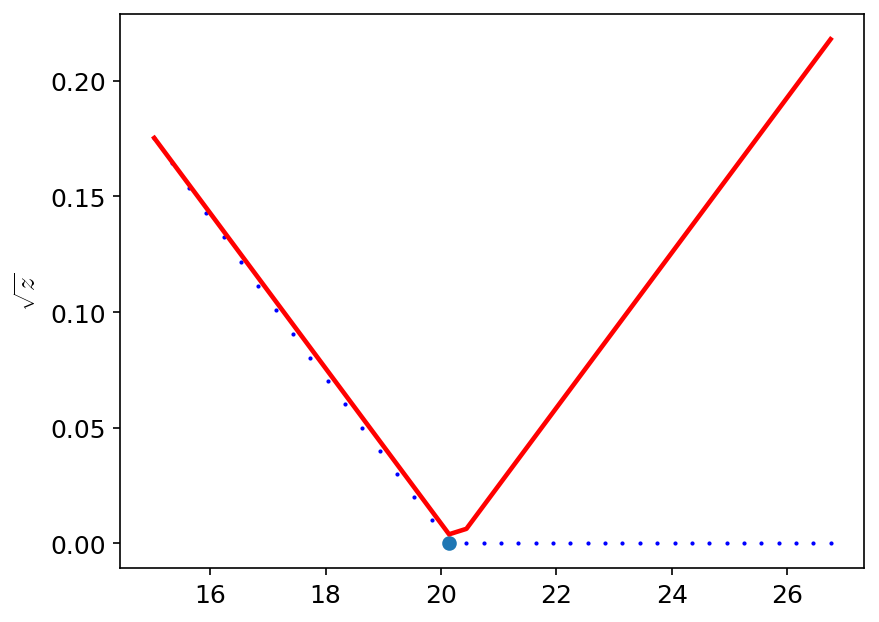

In [137]:
def z_predict(t):
    #t_nat = t * 1.52e21
    #z_nat = (np.sqrt(z_1*1e18/const.MeV_fm) - C*(t_nat - t_1*1.52e21)/2)**2
    #return z_nat * const.MeV_fm / 1e18
    return (np.sqrt(z_1) - C*(t - t_1)/2)**2

t_test = tt[10:50]
z_test = zz[10:50]

plt.scatter(t_test, np.sqrt(np.abs(z_test)), c='b', s=1)
plt.scatter(tt[27], zz[27])
plt.plot(t_test, [np.sqrt(np.abs(z_predict(t_test[i]))) for i in range(len(t_test))], 'r')
plt.ylabel(r"$\sqrt{z}$")
#plt.scatter(t_1, 0)

In [96]:
from tqdm import tqdm

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")


def PNM_n(nB, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")

In [97]:
Deln = 0.4*n0
n_crit = 3*n0
T_list = np.logspace(-2,2,200)

muB_N_list = []
muB_Q_list = []
chiK_Q_list = []
nB_N_list = []
nB_Q_list = []

for T in tqdm(T_list):
    # solve for bag constant
    P_crit = PNM_n(n_crit, T)
    P_diff = lambda x: PNM(x, T) - P_crit
    muB_crit = fsolve(P_diff, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
    B_SQM = fsolve(PQM_solve_for_B, 180)[0]
    
    # solve for points Q and N at beta eq.
    DelP = PNM_n(n_crit + Deln, T) - P_crit
    PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]
    
    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]
    
    # calculating aQstar
    if False:
        epsilon = np.sqrt(np.finfo(float).eps)
        muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
        PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
        grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
        nB_Qstar = grad_Qstar[0]
        nK_Qstar = grad_Qstar[1]
        grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
        nB_Q = grad_Q[0]
        nK_Q = grad_Q[1]
        aQstar = (nK_Qstar - nK_Q)/nB_Q  
    
    else:
        PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
        PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
        ddPQM_ddmuK = Derivative(PQM_muK, n=2)
        dPQM_dmuK = Derivative(PQM_muK, n=1)
        dPQM_dmuB = Derivative(PQM_muB, n=1)
        chiK_Q = ddPQM_ddmuK(0)
        nB_Q = dPQM_dmuB(muB_Q)
        nK_Q = dPQM_dmuK(0)
        aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
        muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
        PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit - DelP
        muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]
    
    
    # calculating aN
    PNM_wrap = lambda x: PNM(x, T)
    dPNM_dmuB = Derivative(PNM_wrap, n=1)
    nB_N = dPNM_dmuB(muB_N)
    aN = (nB_N - nK_Q) / nB_Q 

    muB_N_list.append(muB_N)
    muB_Q_list.append(muB_Q)
    chiK_Q_list.append(chiK_Q)
    nB_N_list.append(nB_N)
    nB_Q_list.append(nB_Q)



00%|███████████████████████████████████████████| 200/200 [30:25<00:00,  9.13s/it]

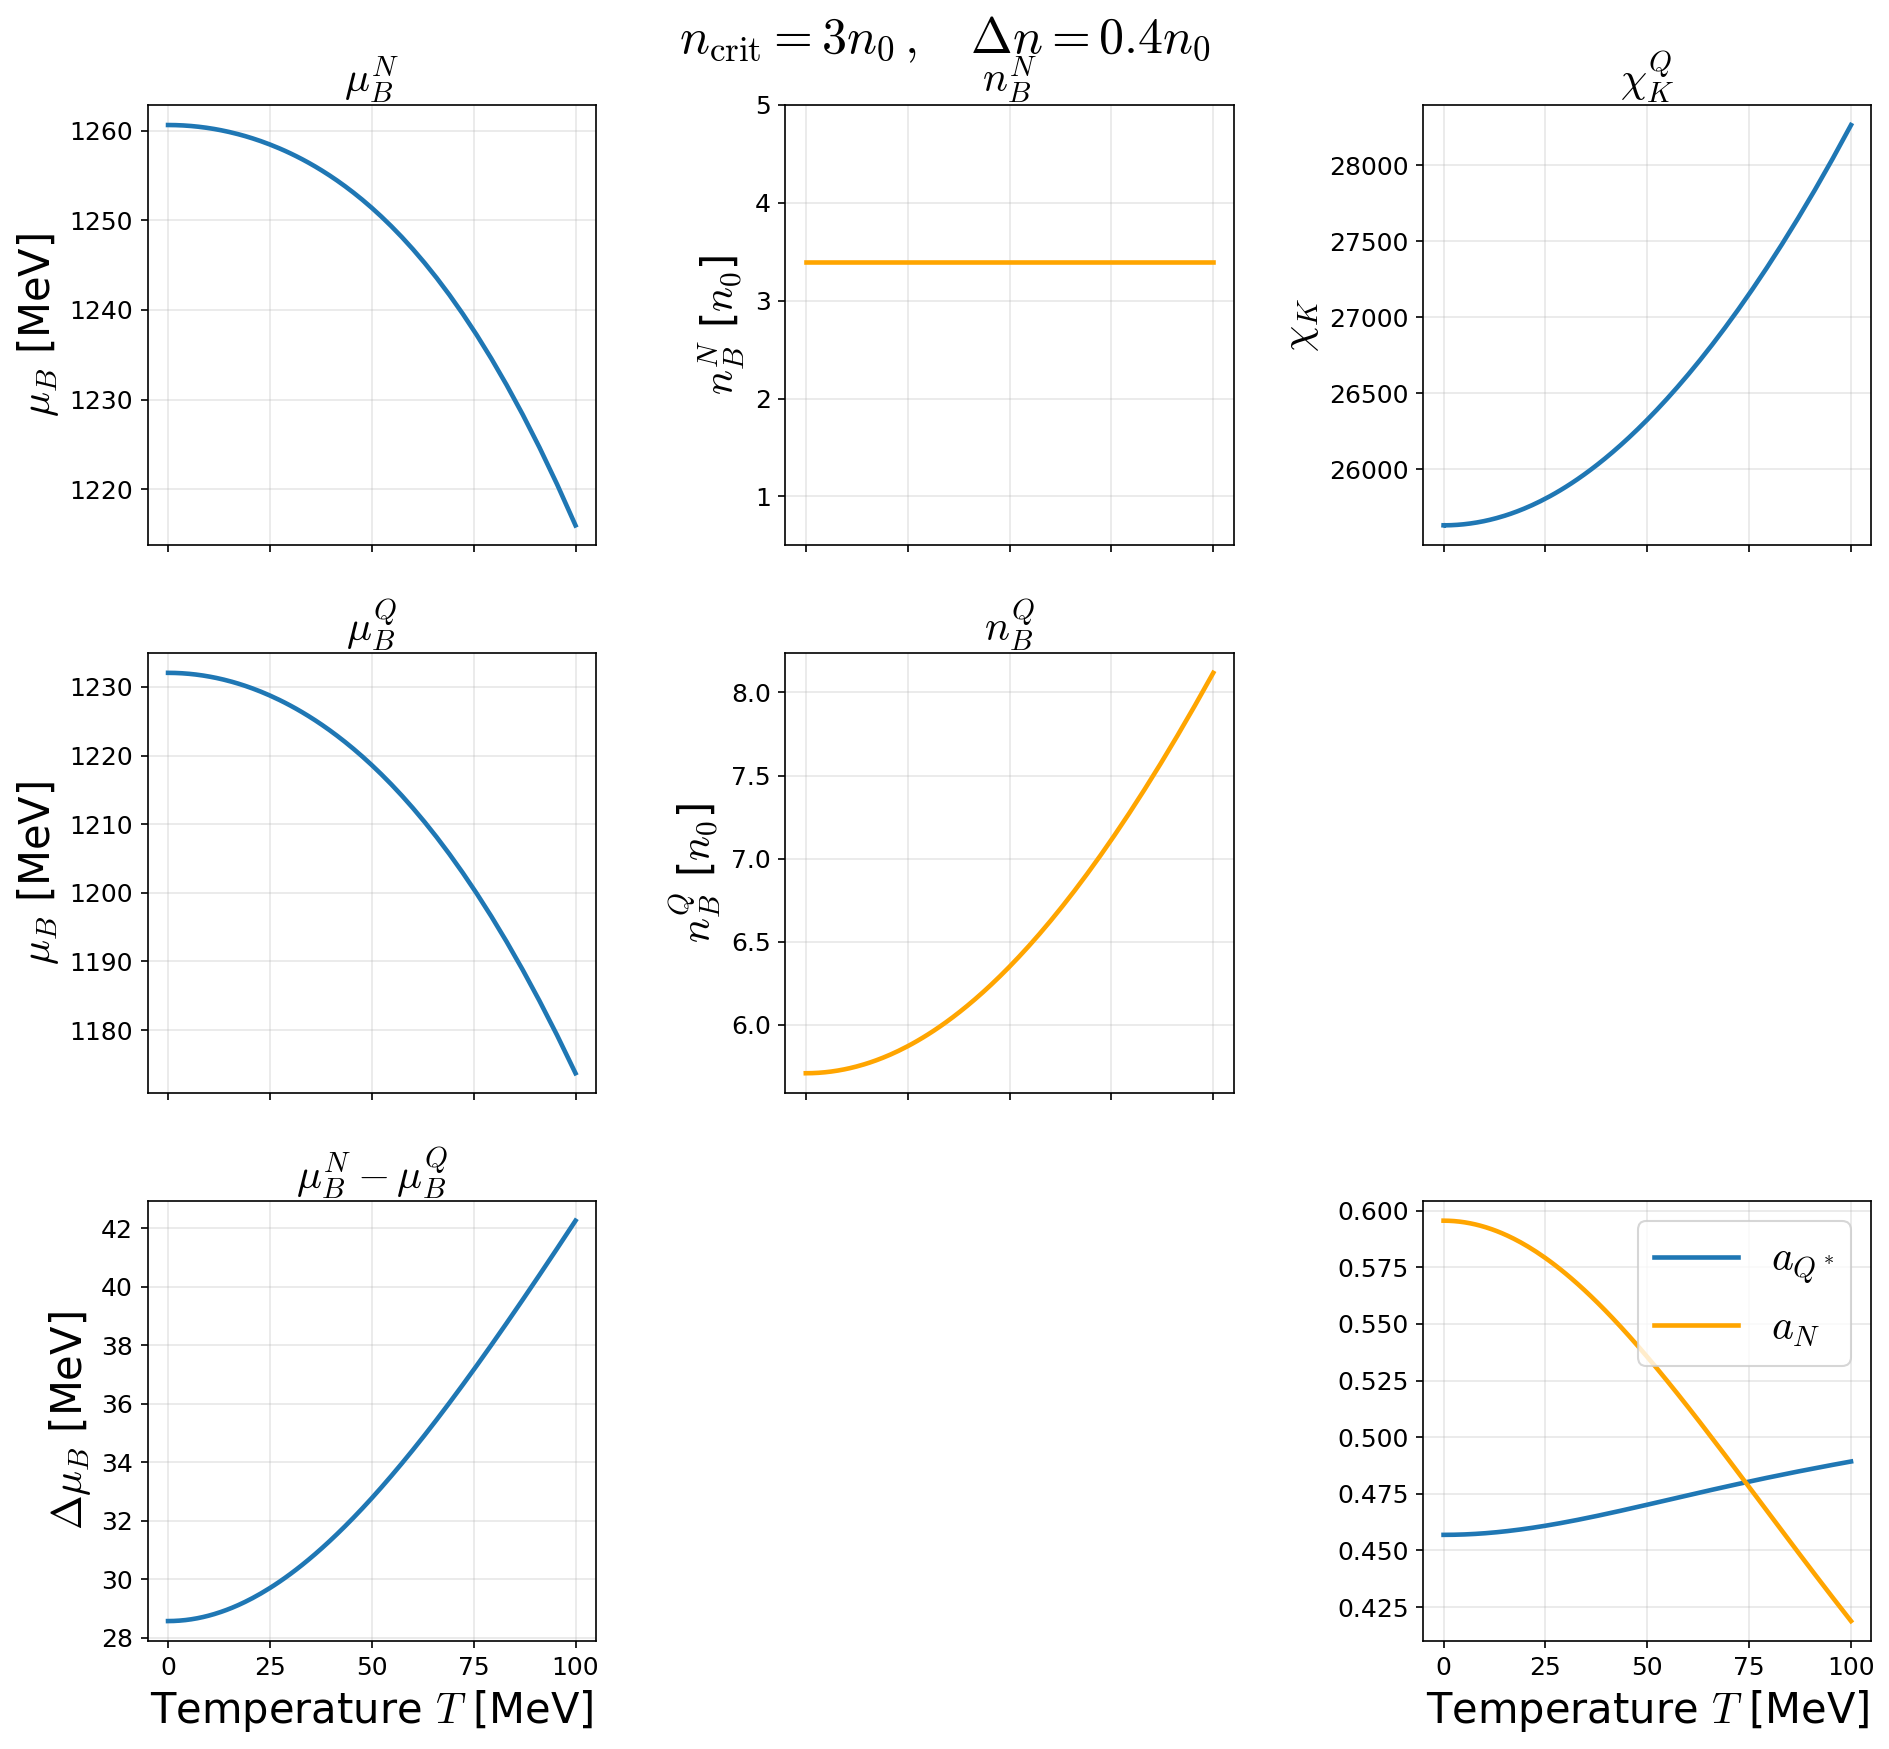

In [147]:
muB_N_list = np.array(muB_N_list)
muB_Q_list = np.array(muB_Q_list)
chiK_Q_list = np.array(chiK_Q_list)
nB_N_list   = np.array(nB_N_list)
nB_Q_list   = np.array(nB_Q_list)

# ---- Normalize number densities by saturation density n0 ----
nB_N_list_n0 = nB_N_list / n0
nB_Q_list_n0 = nB_Q_list / n0

plt.rcParams.update({
    "font.size": 20,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "legend.fontsize": 20,
    "lines.linewidth": 2.2,
    "mathtext.fontset": "cm"
})

fig, ax = plt.subplots(3, 3, figsize=(13, 12), sharex=True)

# ---- Row 1 ----
ax[0,0].plot(T_list, muB_N_list)
ax[0,0].set_title(r"$\mu_B^N$")
ax[0,0].set_ylabel(r"$\mu_B$ [MeV]")
ax[0,0].grid(True, alpha=0.3)

ax[0,1].plot(T_list, nB_N_list_n0, 'orange')
ax[0,1].set_ylim(0.5, 5)
ax[0,1].set_title(r"$n_B^N$")
ax[0,1].set_ylabel(r"$n_B^N$ [$n_0$]")
ax[0,1].grid(True, alpha=0.3)

ax[0,2].plot(T_list, chiK_Q_list)
ax[0,2].set_title(r"$\chi_K^Q$")
ax[0,2].set_ylabel(r"$\chi_K$")
ax[0,2].grid(True, alpha=0.3)

# ---- Row 2 ----
ax[1,0].plot(T_list, muB_Q_list)
ax[1,0].set_title(r"$\mu_B^Q$")
ax[1,0].set_ylabel(r"$\mu_B$ [MeV]")
ax[1,0].grid(True, alpha=0.3)

ax[1,1].plot(T_list, nB_Q_list_n0, 'orange')
ax[1,1].set_title(r"$n_B^Q$")
ax[1,1].set_ylabel(r"$n_B^Q$ [$n_0$]")
ax[1,1].grid(True, alpha=0.3)

ax[1,2].axis("off")

# ---- Row 3 ----
ax[2,0].plot(T_list, muB_N_list - muB_Q_list)
ax[2,0].set_title(r"$\mu_B^N - \mu_B^Q$")
ax[2,0].set_ylabel(r"$\Delta \mu_B$ [MeV]")
ax[2,0].set_xlabel(r"$T$ [MeV]")
ax[2,0].grid(True, alpha=0.3)

#ax[2,1].plot(T_list, nB_N_list/nB_Q_list, 'orange')
#ax[2,1].set_title(r"$a_N$")
#ax[2,1].set_ylabel(r"$\Delta \mu_B$ [MeV]")
#ax[2,1].set_xlabel(r"$T$ [MeV]")
#ax[2,1].grid(True, alpha=0.3)

ax[2,2].plot(T_list, np.sqrt(2*(muB_N_list - muB_Q_list)*chiK_Q_list/nB_Q_list), label = r"$a_{Q^*}$")
ax[2,2].plot(T_list, nB_N_list/nB_Q_list, 'orange', label = r"$a_N$")
#ax[2,2].set_title(r"$a_{Q^*}$")
#ax[2,2].set_ylabel(r"$\Delta \mu_B$ [MeV]")
ax[2,2].set_xlabel(r"$T$ [MeV]")
ax[2,2].grid(True, alpha=0.3)
ax[2,2].legend()

ax[2,1].axis("off")
#ax[2,2].axis("off")

# ---- Shared X label ----
for j in range(3):
    ax[2,j].set_xlabel(r"Temperature $T$ [MeV]")

plt.tight_layout()
plt.subplots_adjust(top=0.93)
fig.suptitle(r"$n_{\rm crit} = 3n_0\,,\quad \Delta n = 0.4n_0$", fontsize=24)
plt.show()

* $n_{\rm crit}(0, B) = xn_0$ fix bag constant